# QDiabetes-2018 Model A — Logistic Recalibration (Method Rehearsal)

**SYNTHETIC — NOT REAL PATIENT DATA**

This notebook demonstrates the **standard logistic-recalibration procedure** for transporting a published risk model to a new population, using the BMI-scoreable eligible cohort and the binary incident-diabetes outcome already defined in `qdiabetes_cohort.py`.

**Framing (read first):**
- Because the outcome is **synthetic**, the recalibrated intercept and slope estimated here are **NOT real-world UAE corrections**. This notebook rehearses the **procedure and its interpretation** for when real NABIDH data arrives.
- The apparent level miscalibration (O:E well below 1.0 in the validation notebook) is **partly confounded with follow-up/horizon mismatch**: QDiabetes predicts **10-year** risk but our synthetic cohort has a median follow-up of ~4.8 years. Some apparent over-prediction reflects shorter observation time, not a true UK→UAE level difference. On real data, use **time-matched evaluation** (or survival recalibration) before interpreting calibration-in-the-large.

**Learning goal:** see how intercept-only recalibration fixes overall level (O:E) while full recalibration fixes both level and spread — and why **none of this changes the C-statistic**.

**Requirements:** `pip install pandas numpy matplotlib seaborn scikit-learn`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from qdiabetes_cohort import (
    build_validation_cohort,
    calibration_slope_logistic,
    load_tables,
    logit_prob,
)

sns.set_theme(style="whitegrid")
SEED = 42
EPS = 1e-6

## Step 1 — Train / test split

BMI-scoreable eligible cohort rows with a defined QDiabetes probability and incident outcome. **70% train / 30% test**, stratified by outcome, `SEED=42`. Recalibration **parameters** are fit on train only; headline **metrics** are on the held-out test set (train metrics shown alongside to reveal optimism).

In [2]:
tables = load_tables("output")
df, eligible, funnel = build_validation_cohort(tables, return_eligible=True, return_funnel=True)

cohort = df.loc[
    df["risk_10y_prob"].notna() & df["outcome_t2d"].notna()
].copy()
print(f"BMI-scoreable cohort with outcome & prediction: {len(cohort):,}")
print(f"Median follow-up (years): {cohort['followup_years'].median():.2f}")

y = cohort["outcome_t2d"].astype(int).to_numpy()
train_idx, test_idx = train_test_split(
    cohort.index,
    test_size=0.30,
    random_state=SEED,
    stratify=y,
)
train = cohort.loc[train_idx].copy()
test = cohort.loc[test_idx].copy()

for name, part in [("Train", train), ("Test", test)]:
    events = int(part["outcome_t2d"].sum())
    print(
        f"{name}: n={len(part):,}, events={events:,}, "
        f"event rate={100 * part['outcome_t2d'].mean():.2f}%"
    )

BMI-scoreable cohort with outcome & prediction: 43,832
Median follow-up (years): 4.81
Train: n=30,682, events=3,142, event rate=10.24%
Test: n=13,150, events=1,347, event rate=10.24%


## Step 2 — Linear predictor

For each patient, let `p` be the QDiabetes predicted probability. Define **LP = logit(p)** with `p` clipped to `[1e-6, 1-1e-6]` first.

In [3]:
def add_lp(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    p = out["risk_10y_prob"].clip(EPS, 1 - EPS)
    out["lp"] = logit_prob(p, eps=EPS)
    return out


train = add_lp(train)
test = add_lp(test)

lp_finite = np.isfinite(train["lp"]).all() and np.isfinite(test["lp"]).all()
print(f"LP finite on train: {np.isfinite(train['lp']).all()}")
print(f"LP finite on test:  {np.isfinite(test['lp']).all()}")
print(f"LP range (train): [{train['lp'].min():.3f}, {train['lp'].max():.3f}]")
assert lp_finite, "LP must be finite for all rows"

LP finite on train: True
LP finite on test:  True
LP range (train): [-7.610, 9.324]


## Step 3 — Fit three models

| Model | Training | Test prediction |
|-------|----------|-----------------|
| **(a) Original** | — | `p` from QDiabetes unchanged |
| **(b) Recalibrated-in-the-large** | Logistic of outcome on LP with **slope fixed at 1** (LP as offset); estimate intercept `a₀` only | `logistic(a₀ + LP)` |
| **(c) Fully recalibrated** | Logistic of outcome on LP; estimate intercept `a` and slope `b` | `logistic(a + b·LP)` |

In [4]:
def logistic(x: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-x))


def fit_intercept_only_offset(lp: np.ndarray, y: np.ndarray, tol: float = 1e-9, max_iter: int = 200) -> float:
    """Fit logit P(y=1) = a0 + lp with slope fixed at 1 (Newton on intercept)."""
    lp = np.asarray(lp, dtype=float)
    y = np.asarray(y, dtype=int)
    a0 = 0.0
    for _ in range(max_iter):
        eta = a0 + lp
        p = logistic(eta)
        w = p * (1 - p)
        grad = np.sum(y - p)
        hess = np.sum(w)
        if hess < 1e-12:
            break
        step = grad / hess
        a0 += step
        if abs(step) < tol:
            break
    return float(a0)


y_train = train["outcome_t2d"].astype(int).to_numpy()
lp_train = train["lp"].to_numpy()
y_test = test["outcome_t2d"].astype(int).to_numpy()
lp_test = test["lp"].to_numpy()

# (a) Original
p_orig_train = train["risk_10y_prob"].to_numpy()
p_orig_test = test["risk_10y_prob"].to_numpy()

# (b) Intercept-only recalibration (slope = 1)
a0 = fit_intercept_only_offset(lp_train, y_train)
p_int_train = logistic(a0 + lp_train)
p_int_test = logistic(a0 + lp_test)

# (c) Full recalibration (intercept + slope)
full_model = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=500)
full_model.fit(lp_train.reshape(-1, 1), y_train)
a_full = float(full_model.intercept_[0])
b_full = float(full_model.coef_[0, 0])
p_full_train = logistic(a_full + b_full * lp_train)
p_full_test = logistic(a_full + b_full * lp_test)

print("Fitted recalibration parameters (train only):")
print(f"  Intercept-only a₀ (slope fixed at 1): {a0:.4f}")
print(f"  Full recalibration intercept a:       {a_full:.4f}")
print(f"  Full recalibration slope b:           {b_full:.4f}")

Fitted recalibration parameters (train only):
  Intercept-only a₀ (slope fixed at 1): -0.4669
  Full recalibration intercept a:       -1.7622
  Full recalibration slope b:           0.1765


## Step 4 — Metrics table (headline)

For each model, on **test** (and **train** for comparison):
- **C-statistic** (AUC)
- **Calibration slope** — logistic regression of outcome on that model's own LP (ideal 1.0)
- **O:E ratio** — mean observed / mean predicted (ideal 1.0), plus mean predicted and mean observed
- **Calibration intercept** — intercept from that same logistic regression (ideal 0.0)

In [5]:
def calibration_intercept(y: np.ndarray, prob: np.ndarray) -> float:
    lp = logit_prob(prob, eps=EPS).reshape(-1, 1)
    y = np.asarray(y, dtype=int)
    if len(np.unique(y)) < 2:
        return np.nan
    m = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=200)
    m.fit(lp, y)
    return float(m.intercept_[0])


def model_metrics(y: np.ndarray, prob: np.ndarray) -> dict:
    y = np.asarray(y, dtype=int)
    prob = np.clip(np.asarray(prob, dtype=float), EPS, 1 - EPS)
    return {
        "c_statistic": roc_auc_score(y, prob),
        "calibration_slope": calibration_slope_logistic(y, prob),
        "calibration_intercept": calibration_intercept(y, prob),
        "oe_ratio": y.mean() / prob.mean(),
        "mean_predicted_pct": 100 * prob.mean(),
        "mean_observed_pct": 100 * y.mean(),
    }


models = {
    "Original": (p_orig_train, p_orig_test),
    "Recalibrated-in-the-large (intercept only)": (p_int_train, p_int_test),
    "Fully recalibrated (intercept + slope)": (p_full_train, p_full_test),
}

rows = []
for model_name, (p_tr, p_te) in models.items():
    for split_name, y_split, p_split in [
        ("Test", y_test, p_te),
        ("Train", y_train, p_tr),
    ]:
        m = model_metrics(y_split, p_split)
        rows.append({"model": model_name, "split": split_name, **m})

metrics_tbl = pd.DataFrame(rows)
display(metrics_tbl.round(4))

test_metrics = metrics_tbl.loc[metrics_tbl["split"] == "Test"].set_index("model")
c_vals = test_metrics["c_statistic"].values
c_spread = c_vals.max() - c_vals.min()
print()
print("Key interpretation (test set):")
print(
    "(1) C-statistic is identical across all three models (to rounding) because recalibration is a "
    "monotonic transformation of the linear predictor — it rescales predicted probabilities but "
    "cannot change the rank order of patients."
)
print(
    f"    Test C-statistics: {', '.join(f'{v:.4f}' for v in c_vals)} (spread {c_spread:.2e})"
)
print(
    "(2) Intercept-only recalibration fixes O:E (level) but leaves calibration slope near the original; "
    "full recalibration adjusts both level and spread — they are separate calibration problems."
)

,model,split,c_statistic,calibration_slope,calibration_intercept,oe_ratio,mean_predicted_pct,mean_observed_pct
0,Original,Test,0.5852,0.2015,-1.7087,0.7238,14.1527,10.2433
1,Original,Train,0.5761,0.1765,-1.7622,0.7211,14.2011,10.2405
2,Recalibrated-in-the-large (intercept only),Test,0.5852,0.2016,-1.6144,1.0058,10.1839,10.2433
3,Recalibrated-in-the-large (intercept only),Train,0.5761,0.1766,-1.6795,1.0000,10.2405,10.2405
4,Fully recalibrated (intercept + slope),Test,0.5852,1.1444,0.3088,1.0002,10.2415,10.2433
5,Fully recalibrated (intercept + slope),Train,0.5761,0.9995,-0.0009,1.0000,10.2408,10.2405



Key interpretation (test set):
(1) C-statistic is identical across all three models (to rounding) because recalibration is a monotonic transformation of the linear predictor — it rescales predicted probabilities but cannot change the rank order of patients.
    Test C-statistics: 0.5852, 0.5852, 0.5852 (spread 0.00e+00)
(2) Intercept-only recalibration fixes O:E (level) but leaves calibration slope near the original; full recalibration adjusts both level and spread — they are separate calibration problems.


## Step 5 — Calibration plot (before / after)

On the **test** set: 10 equal-sized risk bins by predicted probability. Plot mean predicted (x) vs observed event rate (y) with the 45° perfect-calibration line. Overlay **Original** and **Fully recalibrated**.

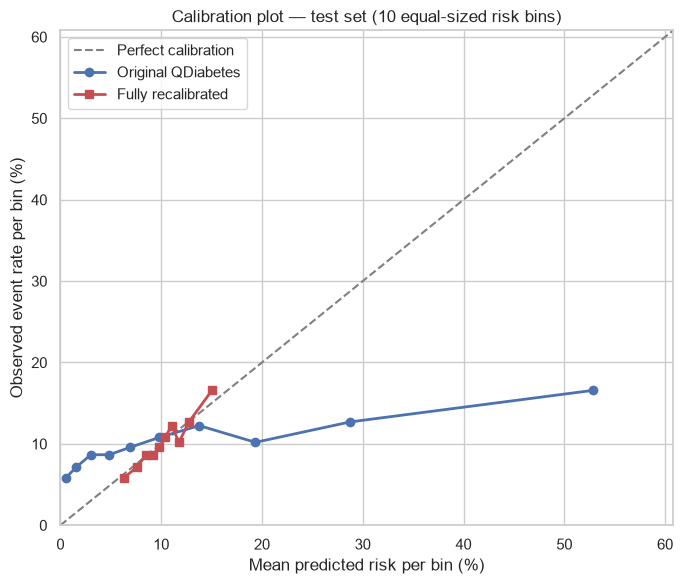

Caption: full recalibration shifts bin-level predictions toward the diagonal — correcting both overall level (O:E) and the slope/spread of the risk–outcome relationship. Discrimination (ranking) is unchanged.


In [6]:
def calibration_by_bins(y: np.ndarray, prob: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    d = pd.DataFrame({"y": y, "prob": prob})
    d["bin"] = pd.qcut(d["prob"], q=n_bins, duplicates="drop")
    return (
        d.groupby("bin", observed=True)
        .agg(
            n=("y", "count"),
            mean_predicted_pct=("prob", lambda s: 100 * s.mean()),
            mean_observed_pct=("y", lambda s: 100 * s.mean()),
        )
        .reset_index(drop=True)
    )


cal_orig = calibration_by_bins(y_test, p_orig_test)
cal_full = calibration_by_bins(y_test, p_full_test)

fig, ax = plt.subplots(figsize=(7, 6))
lim = max(
    cal_orig["mean_predicted_pct"].max(),
    cal_orig["mean_observed_pct"].max(),
    cal_full["mean_predicted_pct"].max(),
    cal_full["mean_observed_pct"].max(),
) * 1.15
ax.plot([0, lim], [0, lim], "--", color="gray", label="Perfect calibration")
ax.plot(
    cal_orig["mean_predicted_pct"],
    cal_orig["mean_observed_pct"],
    "o-",
    color="#4C72B0",
    label="Original QDiabetes",
    linewidth=2,
)
ax.plot(
    cal_full["mean_predicted_pct"],
    cal_full["mean_observed_pct"],
    "s-",
    color="#C44E52",
    label="Fully recalibrated",
    linewidth=2,
)
ax.set_xlabel("Mean predicted risk per bin (%)")
ax.set_ylabel("Observed event rate per bin (%)")
ax.set_title("Calibration plot — test set (10 equal-sized risk bins)")
ax.legend(loc="upper left")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
plt.tight_layout()
plt.show()

print(
    "Caption: full recalibration shifts bin-level predictions toward the diagonal — "
    "correcting both overall level (O:E) and the slope/spread of the risk–outcome relationship. "
    "Discrimination (ranking) is unchanged."
)

## Step 6 — Plain-language conclusion

**What recalibration fixed here:** On this synthetic test set, the original QDiabetes predictions were miscalibrated in **level** (O:E below 1) and **spread** (calibration slope below 1). Intercept-only recalibration corrected the average predicted risk to match observed events; full recalibration additionally stretched/compressed the risk scale so bin-level predictions align better with outcomes.

**What recalibration did not change:** Patient **ranking** and the **C-statistic** — because recalibration is a monotonic remap of the same linear predictor. If a model ranks poorly in a new population (low C-statistic), recalibration cannot fix that; you would need to re-derive coefficients, add predictors, or build a population-specific model.

**Strategic implication for NABIDH:** When real UAE data arrive, this workflow — train/test split, intercept-only then full logistic recalibration on the QDiabetes linear predictor — is the standard first step **after** confirming discrimination is acceptable. But treat any recalibrated parameters as provisional until follow-up is **time-matched** to the model horizon (or survival methods are used). The values printed in this notebook are a **method rehearsal only**, not deployable UAE corrections.

**Horizon caveat:** Mean predicted risks here reflect a 10-year model applied to ~4.8-year follow-up. Before interpreting O:E as a true population level shift, align observation time with the prediction horizon on real data.